In [21]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Experiment Settings
# --------------------------------------------------
N = 5000                    # samples per class
K = 3                       # Gaussian components per class
weights_1 = [0.2, 0.5, 0.3]
weights_2 = [0.4, 0.3, 0.3]

assert np.isclose(sum(weights_1), 1.0)
assert np.isclose(sum(weights_2), 1.0)

print("Class 1 weights:", weights_1)
print("Class 2 weights:", weights_2)

Class 1 weights: [0.2, 0.5, 0.3]
Class 2 weights: [0.4, 0.3, 0.3]


In [ ]:
# --------------------------------------------------
# 2. Custom Uniform Random Number Generator (LCG)
# --------------------------------------------------
seed_state = 12345

def simple_uniform():
    global seed_state
    m = 2**32
    a = 1664525
    c = 1013904223
    seed_state = (a * seed_state + c) % m
    return seed_state / m


# --------------------------------------------------
# 3. Box-Muller Transform
# --------------------------------------------------
def box_muller():
    U1 = simple_uniform()
    U2 = simple_uniform()

    while U1 <= 0:
        U1 = simple_uniform()

    Z1 = np.sqrt(-2 * np.log(U1)) * np.cos(2 * np.pi * U2)
    Z2 = np.sqrt(-2 * np.log(U1)) * np.sin(2 * np.pi * U2)
    return Z1, Z2


def standard_normal_2d(n):
    """Generate n two-dimensional standard-normal samples using Box-Muller."""
    values = np.zeros((n, 2))
    for i in range(n):
        values[i] = box_muller()
    return values


# --------------------------------------------------
# 4. Generate Random Means
# --------------------------------------------------
def generate_means(K, scale=5.5):   # scale chosen empirically to separate the classes
    means = []
    for _ in range(K):
        mx, my = box_muller()
        means.append([scale * mx, scale * my])
    return np.array(means, dtype=float)


means_1 = generate_means(K)
means_2 = generate_means(K)

# Remember the generator state so that data generation (next cells) gives the
# same samples every time, whichever covariance type is selected.
state_after_means = seed_state
print("Class 1 means:\\n", np.round(means_1, 3))
print("Class 2 means:\\n", np.round(means_2, 3))

Class 1 means:\n [[12.487  1.303]
 [-3.29  -3.727]
 [ 1.486  1.269]]
Class 2 means:\n [[ -5.086  -1.594]
 [  0.955  -4.477]
 [ -0.445 -11.416]]


In [23]:
# --------------------------------------------------
# 5. Covariance Matrices
# --------------------------------------------------
# Select ONE covariance experiment at a time:
# "mixed", "spherical", "diagonal", or "full".
# "mixed" (assignment setting): component 1 spherical, component 2 diagonal,
# component 3 full - the same three matrices are used for both classes.
COVARIANCE_TYPE = "mixed"

def make_covariances(kind, K):
    if kind == "mixed":
        return [np.array([[1.0, 0.0], [0.0, 1.0]]),      # component 1: spherical
                np.array([[2.0, 0.0], [0.0, 0.5]]),      # component 2: diagonal
                np.array([[2.0, 0.8], [0.8, 1.0]])]      # component 3: full

    if kind == "spherical":
        base = np.array([[1.0, 0.0], [0.0, 1.0]])
        return [base.copy() for _ in range(K)]

    elif kind == "diagonal":
        # ONE identical diagonal matrix for every component of both classes
        base = np.array([[2.0, 0.0], [0.0, 0.5]])
        return [base.copy() for _ in range(K)]

    elif kind == "full":
        # ONE identical full matrix for every component of both classes
        base = np.array([[2.0, 0.8], [0.8, 1.0]])
        return [base.copy() for _ in range(K)]

    else:
        raise ValueError("COVARIANCE_TYPE must be spherical, diagonal, or full.")


covariances_1 = make_covariances(COVARIANCE_TYPE, K)
covariances_2 = make_covariances(COVARIANCE_TYPE, K)

# Validate covariance matrices
for matrix in covariances_1 + covariances_2:
    if not np.allclose(matrix, matrix.T):
        raise ValueError("Covariance matrix must be symmetric.")
    if np.min(np.linalg.eigvalsh(matrix)) <= 0:
        raise ValueError("Covariance matrix must be positive definite.")

print("Covariance type:", COVARIANCE_TYPE)
print("Class 1 covariance matrices:")
for c in covariances_1:
    print(c)

Covariance type: mixed
Class 1 covariance matrices:
[[1. 0.]
 [0. 1.]]
[[2.  0. ]
 [0.  0.5]]
[[2.  0.8]
 [0.8 1. ]]


In [24]:
# --------------------------------------------------
# 6. Generate Gaussian Mixture Data
# --------------------------------------------------
def generate_data(N, means, weights, covariances):
    data = np.zeros((N, 2))
    component_labels = np.zeros(N, dtype=int)

    # Cumulative weights are used with our own uniform generator.
    cumulative_weights = np.cumsum(weights)

    for i in range(N):
        u = simple_uniform()
        component = np.searchsorted(cumulative_weights, u, side="right")
        component = min(component, len(weights) - 1)

        # Generate standard normal vector using Box-Muller.
        z = np.array(box_muller())

        # Transform N(0,I) into N(mean, covariance).
        eigenvalues, eigenvectors = np.linalg.eigh(covariances[component])
        covariance_sqrt = eigenvectors @ np.diag(np.sqrt(eigenvalues)) @ eigenvectors.T

        data[i] = means[component] + covariance_sqrt @ z
        component_labels[i] = component

    return data, component_labels


# Generate both classes in a fixed sequence (restart from the saved state).
seed_state = state_after_means
X1, components1 = generate_data(N, means_1, weights_1, covariances_1)
X2, components2 = generate_data(N, means_2, weights_2, covariances_2)

y1 = np.zeros(N, dtype=int)
y2 = np.ones(N, dtype=int)

print("Class 1 shape:", X1.shape)
print("Class 2 shape:", X2.shape)
print("Total samples:", len(X1) + len(X2))
print("Class 1 component counts:", np.bincount(components1, minlength=K))
print("Class 2 component counts:", np.bincount(components2, minlength=K))

Class 1 shape: (5000, 2)
Class 2 shape: (5000, 2)
Total samples: 10000
Class 1 component counts: [ 970 2524 1506]
Class 2 component counts: [1991 1517 1492]


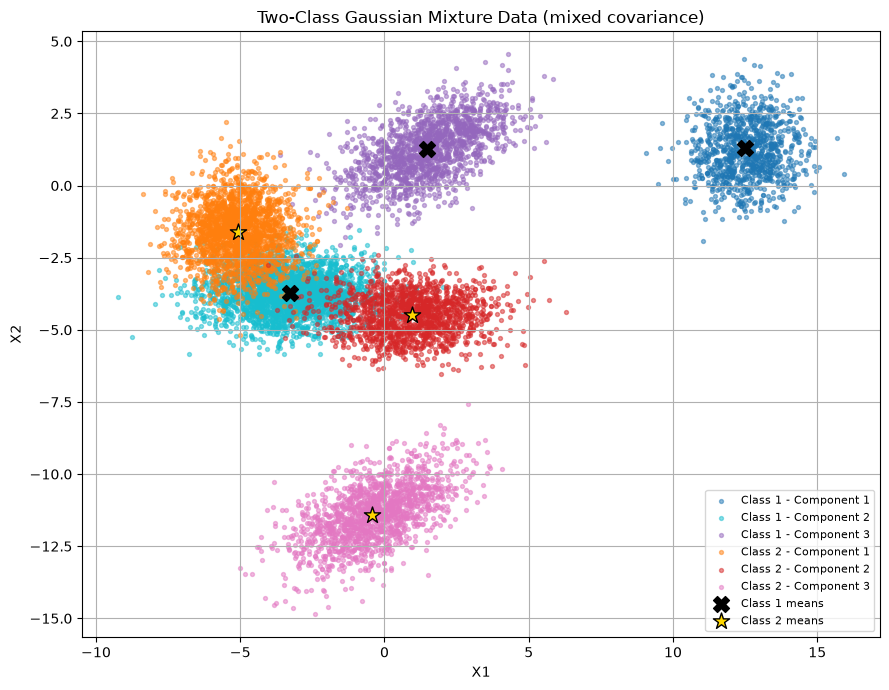

In [25]:
# --------------------------------------------------
# 7. Plot Generated Data by Gaussian Component
# --------------------------------------------------
component_colors = [
    ["tab:blue", "tab:cyan", "tab:purple"],
    ["tab:orange", "tab:red", "tab:pink"]
]

plt.figure(figsize=(9, 7))

for k in range(K):
    selected = components1 == k
    plt.scatter(X1[selected, 0], X1[selected, 1], s=8, alpha=0.5,
                color=component_colors[0][k], label=f"Class 1 - Component {k+1}")

for k in range(K):
    selected = components2 == k
    plt.scatter(X2[selected, 0], X2[selected, 1], s=8, alpha=0.5,
                color=component_colors[1][k], label=f"Class 2 - Component {k+1}")

plt.scatter(means_1[:, 0], means_1[:, 1], marker="X", s=130,
            color="black", label="Class 1 means")
plt.scatter(means_2[:, 0], means_2[:, 1], marker="*", s=150,
            color="gold", edgecolor="black", label="Class 2 means")

plt.xlabel("X1")
plt.ylabel("X2")
plt.title(f"Two-Class Gaussian Mixture Data ({COVARIANCE_TYPE} covariance)")
plt.legend(fontsize=8)
plt.grid(True)
plt.axis("equal")
plt.tight_layout()
plt.show()

In [26]:
# --------------------------------------------------
# 8. 80:20 Train-Test Split
# --------------------------------------------------
split_rng = np.random.default_rng(44)
train_size = int(0.8 * N)

indices1 = split_rng.permutation(N)
indices2 = split_rng.permutation(N)

X1_train, X1_test = X1[indices1[:train_size]], X1[indices1[train_size:]]
X2_train, X2_test = X2[indices2[:train_size]], X2[indices2[train_size:]]

train_class_samples = [X1_train, X2_train]
test_class_samples = [X1_test, X2_test]

print("Class 1 train/test:", X1_train.shape, X1_test.shape)
print("Class 2 train/test:", X2_train.shape, X2_test.shape)

Class 1 train/test: (4000, 2) (1000, 2)
Class 2 train/test: (4000, 2) (1000, 2)


In [27]:
# --------------------------------------------------
# 9. Custom K-Means Implementation
# --------------------------------------------------
class KMeans:
    def __init__(self, K=3, max_iter=100, tol=1e-6, random_state=42):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centers = None

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)
        indices = rng.choice(len(X), size=self.K, replace=False)
        self.centers = X[indices].astype(float)

        for _ in range(self.max_iter):
            labels = self.predict(X)
            new_centers = self.centers.copy()

            for k in range(self.K):
                points = X[labels == k]
                if len(points) > 0:
                    new_centers[k] = points.mean(axis=0)

            converged = np.max(np.abs(self.centers - new_centers)) < self.tol
            self.centers = new_centers
            if converged:
                break

        return self

    def predict(self, X):
        if self.centers is None:
            raise ValueError("Call fit() before predict().")

        distances = np.sum((X[:, None, :] - self.centers[None, :, :])**2, axis=2)
        return np.argmin(distances, axis=1)


# --------------------------------------------------
# 10. Train one K-Means model per class
# --------------------------------------------------
class_models = []

for class_index, samples in enumerate(train_class_samples):
    model = KMeans(K=K)
    model.fit(samples)
    class_models.append(model)
    print(f"Class {class_index + 1} cluster centres:\\n",
          np.round(model.centers, 3))

Class 1 cluster centres:\n [[12.527  1.224]
 [ 1.551  1.285]
 [-3.29  -3.722]]
Class 2 cluster centres:\n [[ -5.06   -1.63 ]
 [  0.97   -4.485]
 [ -0.393 -11.368]]


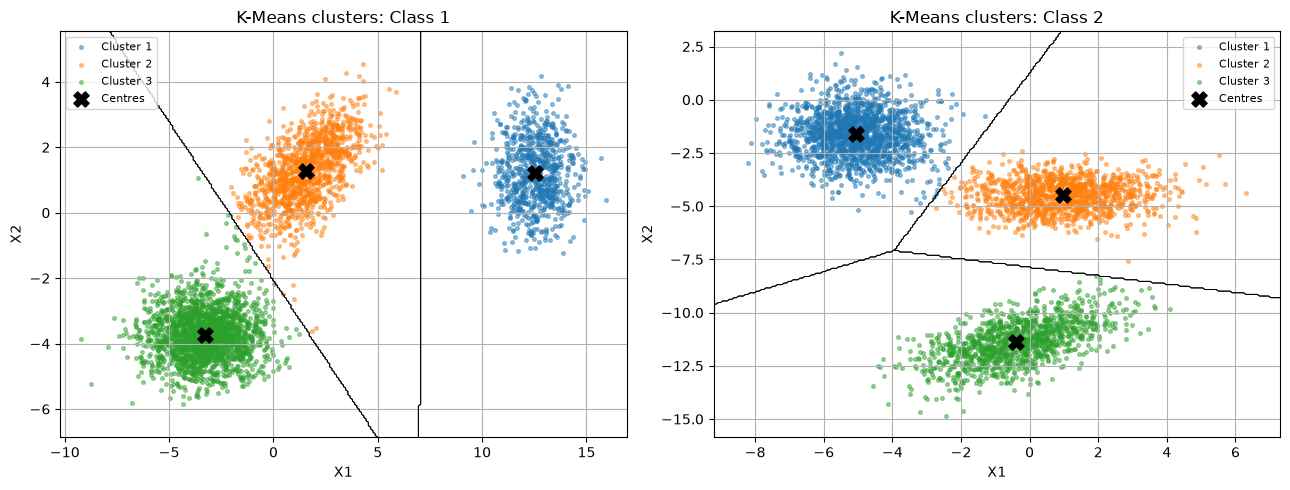

In [28]:
# --------------------------------------------------
# 11. Plot K-Means clusters and within-class boundaries
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for class_index, (ax, model, samples) in enumerate(
        zip(axes, class_models, train_class_samples)):

    labels = model.predict(samples)
    x_min, x_max = samples[:, 0].min() - 1, samples[:, 0].max() + 1
    y_min, y_max = samples[:, 1].min() - 1, samples[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    grid_labels = model.predict(grid).reshape(xx.shape)

    for k in range(K):
        pts = samples[labels == k]
        ax.scatter(pts[:, 0], pts[:, 1], s=7, alpha=0.45,
                   label=f"Cluster {k+1}")
        ax.contour(xx, yy, grid_labels == k, levels=[0.5],
                   colors="black", linewidths=0.7)

    ax.scatter(model.centers[:, 0], model.centers[:, 1],
               marker="X", s=120, color="black", label="Centres")
    ax.set_title(f"K-Means clusters: Class {class_index+1}")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend(fontsize=8)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [29]:
# --------------------------------------------------
# 12. Test Classification Using Minimum Distortion
# --------------------------------------------------
# Distortion for class c: minimum squared distance to its K centroids.
def class_distortion(X, model):
    distances = np.sum(
        (X[:, None, :] - model.centers[None, :, :])**2,
        axis=2
    )
    return np.min(distances, axis=1)


X_test_all = np.vstack((X1_test, X2_test))
y_test_all = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

distortion_scores = np.column_stack([
    class_distortion(X_test_all, model) for model in class_models
])

y_pred = np.argmin(distortion_scores, axis=1)

cm = np.zeros((2, 2), dtype=int)
for actual, predicted in zip(y_test_all, y_pred):
    cm[actual, predicted] += 1

accuracy = np.trace(cm) / cm.sum()

print("Confusion matrix (rows=true, columns=predicted):\\n", cm)
print(f"Accuracy: {accuracy:.4%}")

Confusion matrix (rows=true, columns=predicted):\n [[913  87]
 [ 45 955]]
Accuracy: 93.4000%


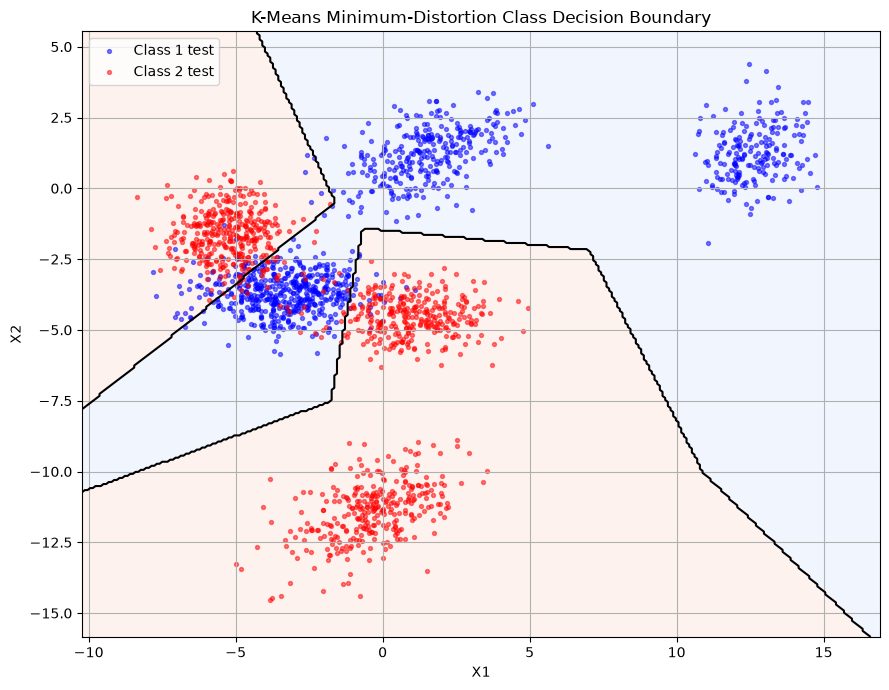

In [30]:
# --------------------------------------------------
# 13. Plot Decision Boundary Between the Two Classes
# --------------------------------------------------
all_data = np.vstack((X1, X2))
x_min, x_max = all_data[:, 0].min() - 1, all_data[:, 0].max() + 1
y_min, y_max = all_data[:, 1].min() - 1, all_data[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = np.column_stack((xx.ravel(), yy.ravel()))

grid_scores = np.column_stack([
    class_distortion(grid, model) for model in class_models
])
grid_prediction = np.argmin(grid_scores, axis=1).reshape(xx.shape)

plt.figure(figsize=(9, 7))
plt.contourf(xx, yy, grid_prediction, levels=[-0.5, 0.5, 1.5],
             alpha=0.12, cmap="coolwarm")
plt.contour(xx, yy, grid_prediction, levels=[0.5],
            colors="black", linewidths=1.5)

plt.scatter(X1_test[:, 0], X1_test[:, 1], s=8, alpha=0.5,
            label="Class 1 test", color="blue")
plt.scatter(X2_test[:, 0], X2_test[:, 1], s=8, alpha=0.5,
            label="Class 2 test", color="red")

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("K-Means Minimum-Distortion Class Decision Boundary")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()